In [3]:
import os

PROJECT_DIR = "/content/Sales_Business_Analytics"

folders = [
    "data/raw",
    "data/interim",
    "data/processed",
    "notebooks",
    "reports/figures",
    "src"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project workspace created successfully!")

Project workspace created successfully!


In [4]:

from google.colab import files
import shutil
import os

uploaded = files.upload()

for filename in uploaded.keys():
    shutil.move(
        filename,
        os.path.join(PROJECT_DIR, "data/raw", filename)
    )

print("Dataset uploaded successfully!")


Saving Sample - Superstore.xlsm to Sample - Superstore.xlsm
Dataset uploaded successfully!


In [5]:
import os

raw_path = os.path.join(PROJECT_DIR, "data/raw")

print("Files in raw directory:")
print(os.listdir(raw_path))

Files in raw directory:
['Sample - Superstore.xlsm']


In [6]:

import pandas as pd
import os

file_path = os.path.join(
    PROJECT_DIR,
    "data/raw",
    "Sample - Superstore.xlsm"
)

# Read all Excel sheets
excel = pd.ExcelFile(file_path)

print("Available Sheets:", excel.sheet_names)

for sheet in excel.sheet_names:
    df = pd.read_excel(file_path, sheet_name=sheet)

    print(f"\n{'='*50}")
    print("SHEET:", sheet)
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nData Types:")
    print(df.dtypes)
    print("\nFirst 5 Records:")
    display(df.head())


Available Sheets: ['Orders', 'Returns', 'People']

SHEET: Orders
Shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data Types:
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code               int64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                fl

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



SHEET: Returns
Shape: (296, 2)

Columns:
['Returned', 'Order ID']

Data Types:
Returned    object
Order ID    object
dtype: object

First 5 Records:


,Returned,Order ID
0,Yes,CA-2017-153822
1,Yes,CA-2017-129707
2,Yes,CA-2014-152345
3,Yes,CA-2015-156440
4,Yes,US-2017-155999



SHEET: People
Shape: (4, 2)

Columns:
['Person', 'Region']

Data Types:
Person    object
Region    object
dtype: object

First 5 Records:


,Person,Region
0,Anna Andreadi,West
1,Chuck Magee,East
2,Kelly Williams,Central
3,Cassandra Brandow,South


In [7]:

import pandas as pd
import os

file_path = os.path.join(
    PROJECT_DIR,
    "data/raw",
    "Sample - Superstore.xlsm"
)

orders = pd.read_excel(file_path, sheet_name="Orders")
returns = pd.read_excel(file_path, sheet_name="Returns")
people = pd.read_excel(file_path, sheet_name="People")

# 1. Missing values
print("MISSING VALUES:")
print(orders.isnull().sum())

# 2. Duplicate records
print("\nDUPLICATE ROWS:", orders.duplicated().sum())
print("DUPLICATE ROW IDs:", orders["Row ID"].duplicated().sum())

# 3. Numeric column checks
print("\nNUMERIC SUMMARY:")
display(orders[["Sales", "Quantity", "Discount", "Profit"]].describe())

# 4. Invalid values
print("\nINVALID VALUE CHECKS:")
print("Sales <= 0:", (orders["Sales"] <= 0).sum())
print("Quantity <= 0:", (orders["Quantity"] <= 0).sum())
print("Discount < 0:", (orders["Discount"] < 0).sum())
print("Discount > 1:", (orders["Discount"] > 1).sum())

# 5. Date range
print("\nDATE RANGE:")
print("Earliest Order:", orders["Order Date"].min())
print("Latest Order:", orders["Order Date"].max())

# 6. Return information
print("\nRETURN SHEET:")
print("Total return records:", len(returns))
print("Unique returned orders:", returns["Order ID"].nunique())

# 7. Unique categories
print("\nCATEGORIES:", orders["Category"].unique())
print("REGIONS:", orders["Region"].unique())
print("SEGMENTS:", orders["Segment"].unique())


MISSING VALUES:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

DUPLICATE ROWS: 0
DUPLICATE ROW IDs: 0

NUMERIC SUMMARY:


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000



INVALID VALUE CHECKS:
Sales <= 0: 0
Quantity <= 0: 0
Discount < 0: 0
Discount > 1: 0

DATE RANGE:
Earliest Order: 2014-01-03 00:00:00
Latest Order: 2017-12-30 00:00:00

RETURN SHEET:
Total return records: 296
Unique returned orders: 296

CATEGORIES: ['Furniture' 'Office Supplies' 'Technology']
REGIONS: ['South' 'West' 'Central' 'East']
SEGMENTS: ['Consumer' 'Corporate' 'Home Office']


In [8]:

# 1. Understand transaction granularity
print("Total transaction rows:", len(orders))
print("Unique orders:", orders["Order ID"].nunique())
print("Unique customers:", orders["Customer ID"].nunique())
print("Unique products:", orders["Product ID"].nunique())

# 2. Check multiple rows per order
order_rows = orders.groupby("Order ID").size()

print("\nOrders with multiple product rows:", (order_rows > 1).sum())
print("Maximum rows in a single order:", order_rows.max())

# 3. Validate return records against Orders
returned_order_ids = set(returns["Order ID"])
all_order_ids = set(orders["Order ID"])

print("\nReturn validation:")
print("Return IDs not found in Orders:",
      len(returned_order_ids - all_order_ids))

print("Orders marked as returned:",
      orders["Order ID"].isin(returned_order_ids).sum())

# 4. Check profit and sales totals
print("\nFinancial Summary:")
print("Total Sales:", round(orders["Sales"].sum(), 2))
print("Total Profit:", round(orders["Profit"].sum(), 2))
print("Total Quantity:", orders["Quantity"].sum())

# 5. Check shipping date consistency
print("\nShip date before order date:",
      (orders["Ship Date"] < orders["Order Date"]).sum())


Total transaction rows: 9994
Unique orders: 5009
Unique customers: 793
Unique products: 1862

Orders with multiple product rows: 2471
Maximum rows in a single order: 14

Return validation:
Return IDs not found in Orders: 0
Orders marked as returned: 800

Financial Summary:
Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity: 37873

Ship date before order date: 0


In [9]:

total_sales = orders["Sales"].sum()
total_profit = orders["Profit"].sum()
total_orders = orders["Order ID"].nunique()
total_customers = orders["Customer ID"].nunique()

baseline_kpis = {
    "Total Sales": total_sales,
    "Total Profit": total_profit,
    "Total Orders": total_orders,
    "Total Customers": total_customers,
    "Average Order Value": total_sales / total_orders,
    "Profit Margin (%)": (total_profit / total_sales) * 100,
    "Total Quantity Sold": orders["Quantity"].sum()
}

print("BASELINE BUSINESS KPIs")
print("-" * 40)

for kpi, value in baseline_kpis.items():
    print(f"{kpi}: {value:,.2f}")


BASELINE BUSINESS KPIs
----------------------------------------
Total Sales: 2,297,200.86
Total Profit: 286,397.02
Total Orders: 5,009.00
Total Customers: 793.00
Average Order Value: 458.61
Profit Margin (%): 12.47
Total Quantity Sold: 37,873.00


In [10]:

import os
import pandas as pd

# Reload source data
file_path = os.path.join(
    PROJECT_DIR, "data/raw", "Sample - Superstore.xlsm"
)

orders = pd.read_excel(file_path, sheet_name="Orders")
returns = pd.read_excel(file_path, sheet_name="Returns")
people = pd.read_excel(file_path, sheet_name="People")

# Standardize column names
for df in [orders, returns, people]:
    df.columns = df.columns.str.strip()

# Standardize text columns
for df in [orders, returns, people]:
    text_cols = df.select_dtypes(include="object").columns
    for col in text_cols:
        df[col] = df[col].str.strip()

# Ensure correct data types
orders["Order Date"] = pd.to_datetime(orders["Order Date"])
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"])

orders["Postal Code"] = orders["Postal Code"].astype(str)

# Add return indicator using Returns sheet
returned_ids = set(returns["Order ID"])
orders["Returned"] = orders["Order ID"].isin(returned_ids)

# Save cleaned datasets
processed_dir = os.path.join(PROJECT_DIR, "data/processed")

orders.to_csv(os.path.join(processed_dir, "orders_clean.csv"), index=False)
returns.to_csv(os.path.join(processed_dir, "returns_clean.csv"), index=False)
people.to_csv(os.path.join(processed_dir, "people_clean.csv"), index=False)

print("Cleaned datasets saved successfully!")
print("Orders:", orders.shape)
print("Returns:", returns.shape)
print("People:", people.shape)
print("Returned orders:", orders.loc[orders["Returned"], "Order ID"].nunique())


Cleaned datasets saved successfully!
Orders: (9994, 22)
Returns: (296, 2)
People: (4, 2)
Returned orders: 296


In [11]:

processed_dir = os.path.join(PROJECT_DIR, "data/processed")

orders_check = pd.read_csv(
    os.path.join(processed_dir, "orders_clean.csv"),
    parse_dates=["Order Date", "Ship Date"]
)

returns_check = pd.read_csv(
    os.path.join(processed_dir, "returns_clean.csv")
)

people_check = pd.read_csv(
    os.path.join(processed_dir, "people_clean.csv")
)

print("ORDERS:", orders_check.shape)
print("RETURNS:", returns_check.shape)
print("PEOPLE:", people_check.shape)

print("\nVALIDATION:")
print("Total Sales:", round(orders_check["Sales"].sum(), 2))
print("Total Profit:", round(orders_check["Profit"].sum(), 2))
print("Unique Orders:", orders_check["Order ID"].nunique())
print("Unique Returned Orders:",
      orders_check.loc[orders_check["Returned"], "Order ID"].nunique())

print("\nMissing Values:", orders_check.isnull().sum().sum())


ORDERS: (9994, 22)
RETURNS: (296, 2)
PEOPLE: (4, 2)

VALIDATION:
Total Sales: 2297200.86
Total Profit: 286397.02
Unique Orders: 5009
Unique Returned Orders: 296

Missing Values: 0


,Category,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,741999.80,18451.27,8028
1,Office Supplies,719047.03,122490.80,22906
2,Technology,836154.03,145454.95,6939


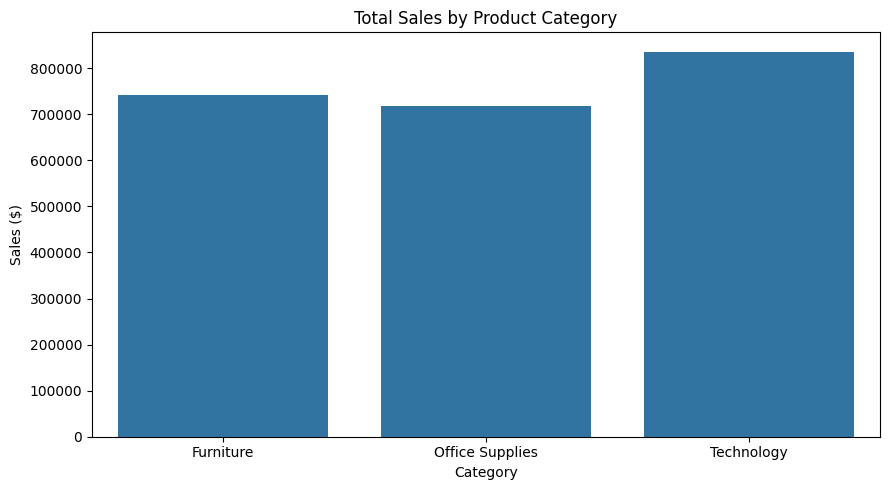

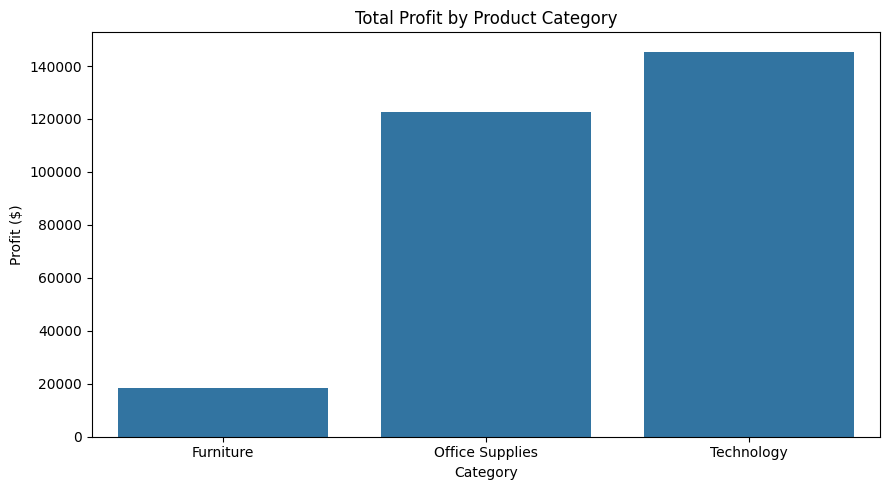

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

# Category-wise aggregation
category_summary = (
    orders.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

display(category_summary.round(2))

# Sales by category
plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_summary,
    x="Category",
    y="Total_Sales"
)
plt.title("Total Sales by Product Category")
plt.ylabel("Sales ($)")
plt.xlabel("Category")
plt.tight_layout()
plt.show()

# Profit by category
plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_summary,
    x="Category",
    y="Total_Profit"
)
plt.title("Total Profit by Product Category")
plt.ylabel("Profit ($)")
plt.xlabel("Category")
plt.tight_layout()
plt.show()


,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
2,Technology,836154.03,145454.95,6939,17.40
1,Office Supplies,719047.03,122490.80,22906,17.04
0,Furniture,741999.80,18451.27,8028,2.49


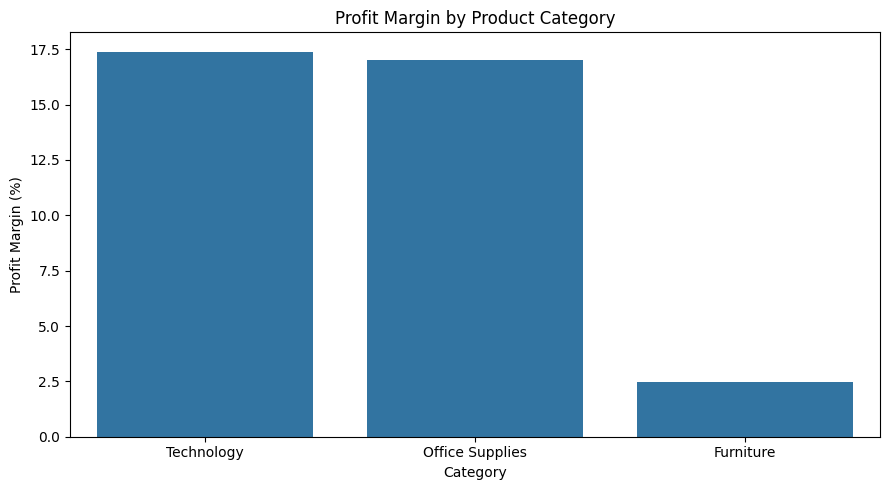

In [13]:

category_summary["Profit_Margin"] = (
    category_summary["Total_Profit"] /
    category_summary["Total_Sales"]
) * 100

category_summary = category_summary.sort_values(
    "Profit_Margin", ascending=False
)

display(category_summary.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_summary,
    x="Category",
    y="Profit_Margin"
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()


,YearMonth,Total_Sales,Total_Profit
0,2014-01,14236.8950,2450.1907
1,2014-02,4519.8920,862.3084
2,2014-03,55691.0090,498.7299
3,2014-04,28295.3450,3488.8352
4,2014-05,23648.2870,2738.7096
5,2014-06,34595.1276,4976.5244
6,2014-07,33946.3930,-841.4826
7,2014-08,27909.4685,5318.1050
8,2014-09,81777.3508,8328.0994
9,2014-10,31453.3930,3448.2573


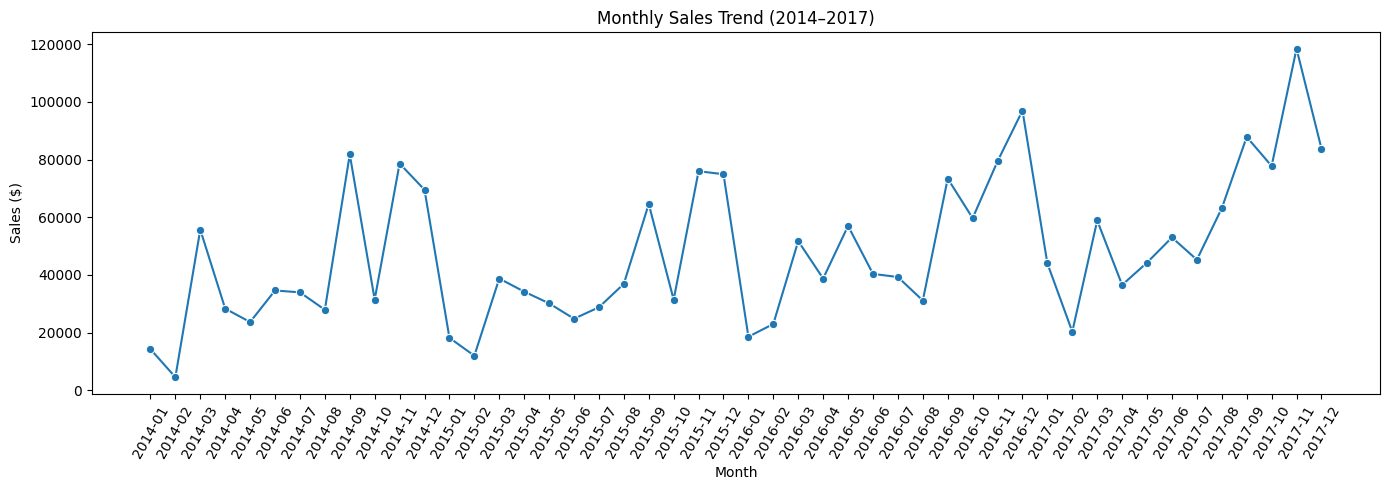

In [14]:

orders["YearMonth"] = orders["Order Date"].dt.to_period("M")

monthly_sales = (
    orders.groupby("YearMonth")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

monthly_sales["YearMonth"] = (
    monthly_sales["YearMonth"].astype(str)
)

display(monthly_sales.head(12))

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


In [15]:

# Highest and lowest sales months
highest_sales = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

lowest_sales = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

# Highest and lowest profit months
highest_profit = monthly_sales.loc[
    monthly_sales["Total_Profit"].idxmax()
]

lowest_profit = monthly_sales.loc[
    monthly_sales["Total_Profit"].idxmin()
]

print("HIGHEST SALES MONTH:")
print(highest_sales)

print("\nLOWEST SALES MONTH:")
print(lowest_sales)

print("\nHIGHEST PROFIT MONTH:")
print(highest_profit)

print("\nLOWEST PROFIT MONTH:")
print(lowest_profit)


HIGHEST SALES MONTH:
YearMonth          2017-11
Total_Sales     118447.825
Total_Profit     9690.1037
Name: 46, dtype: object

LOWEST SALES MONTH:
YearMonth        2014-02
Total_Sales     4519.892
Total_Profit    862.3084
Name: 1, dtype: object

HIGHEST PROFIT MONTH:
YearMonth          2016-12
Total_Sales      96999.043
Total_Profit    17885.3093
Name: 35, dtype: object

LOWEST PROFIT MONTH:
YearMonth          2015-01
Total_Sales     18174.0756
Total_Profit     -3281.007
Name: 12, dtype: object


,Year,Total_Sales,Total_Profit,Total_Orders,Sales_Growth_%,Profit_Growth_%
0,2014,484247.50,49543.97,969,NaN,NaN
1,2015,470532.51,61618.60,1038,-2.83,24.37
2,2016,609205.60,81795.17,1315,29.47,32.74
3,2017,733215.26,93439.27,1687,20.36,14.24


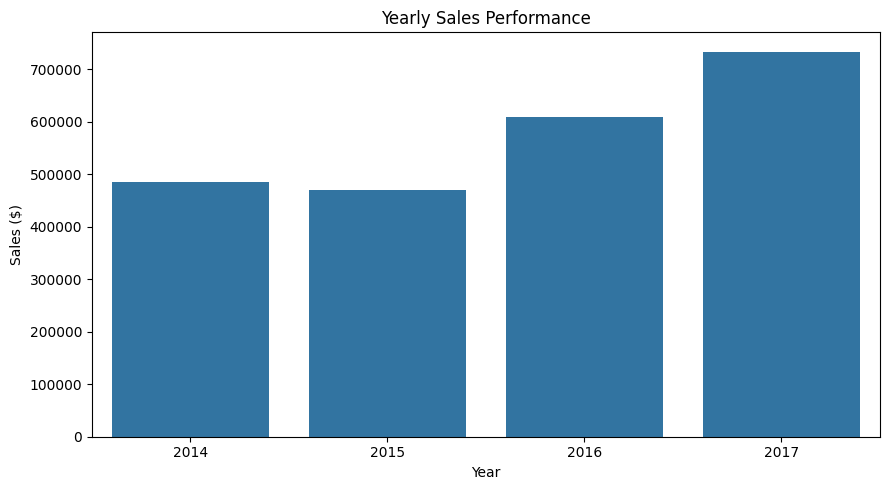

In [16]:

orders["Year"] = orders["Order Date"].dt.year

yearly_summary = (
    orders.groupby("Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

yearly_summary["Sales_Growth_%"] = (
    yearly_summary["Total_Sales"].pct_change() * 100
)

yearly_summary["Profit_Growth_%"] = (
    yearly_summary["Total_Profit"].pct_change() * 100
)

display(yearly_summary.round(2))

# Annual sales trend
plt.figure(figsize=(9, 5))
sns.barplot(
    data=yearly_summary,
    x="Year",
    y="Total_Sales"
)
plt.title("Yearly Sales Performance")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()


,Region,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%
3,West,725457.82,108418.45,1611,12266,14.94
1,East,678781.24,91522.78,1401,10618,13.48
0,Central,501239.89,39706.36,1175,8780,7.92
2,South,391721.90,46749.43,822,6209,11.93


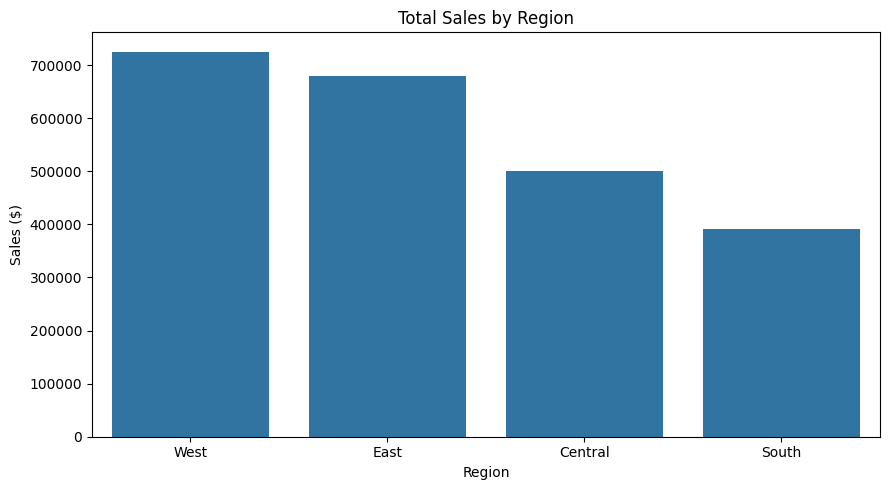

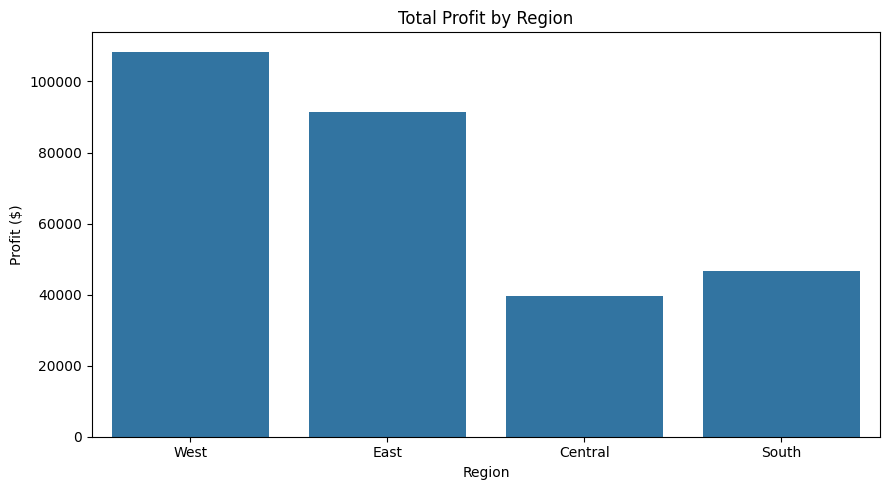

In [17]:

region_summary = (
    orders.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

region_summary["Profit_Margin_%"] = (
    region_summary["Total_Profit"] /
    region_summary["Total_Sales"]
) * 100

region_summary = region_summary.sort_values(
    "Total_Sales", ascending=False
)

display(region_summary.round(2))

# Regional sales comparison
plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_summary,
    x="Region",
    y="Total_Sales"
)
plt.title("Total Sales by Region")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()

# Regional profit comparison
plt.figure(figsize=(9, 5))
sns.barplot(
    data=region_summary,
    x="Region",
    y="Total_Profit"
)
plt.title("Total Profit by Region")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()


,Segment,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit_Margin_%,AOV
0,Consumer,1161401.34,134119.21,2586,409,11.55,449.11
1,Corporate,706146.37,91979.13,1514,236,13.03,466.41
2,Home Office,429653.15,60298.68,909,148,14.03,472.67


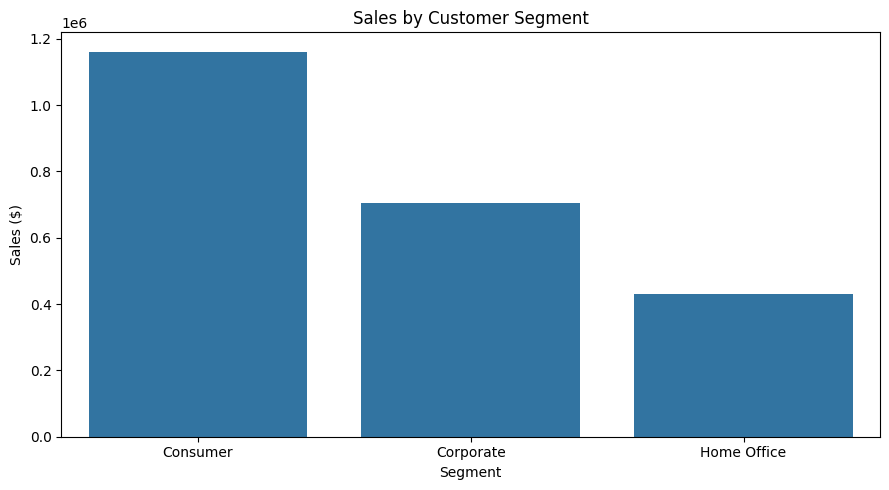

In [18]:

segment_summary = (
    orders.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

segment_summary["Profit_Margin_%"] = (
    segment_summary["Total_Profit"] /
    segment_summary["Total_Sales"]
) * 100

segment_summary["AOV"] = (
    segment_summary["Total_Sales"] /
    segment_summary["Total_Orders"]
)

display(segment_summary.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=segment_summary,
    x="Segment",
    y="Total_Sales"
)
plt.title("Sales by Customer Segment")
plt.ylabel("Sales ($)")
plt.tight_layout()
plt.show()


In [19]:

product_summary = (
    orders.groupby(["Product ID", "Product Name", "Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .reset_index()
)

# Top 10 products by sales
top_sales = product_summary.nlargest(10, "Total_Sales")

print("TOP 10 PRODUCTS BY SALES")
display(top_sales.round(2))

# Top 10 products by profit
top_profit = product_summary.nlargest(10, "Total_Profit")

print("\nTOP 10 PRODUCTS BY PROFIT")
display(top_profit.round(2))


TOP 10 PRODUCTS BY SALES


,Product ID,Product Name,Category,Total_Sales,Total_Profit,Total_Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,31
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.48,-1811.08,6
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.58,0.00,39
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.48,2233.51,37
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,19024.50,760.98,48
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,18839.69,6983.88,38
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.90,4094.98,12
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,17965.07,-1878.17,27
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,Office Supplies,17030.31,-262.00,11



TOP 10 PRODUCTS BY PROFIT


,Product ID,Product Name,Category,Total_Sales,Total_Profit,Total_Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,31
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,18839.69,6983.88,38
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,Technology,11619.83,4570.93,19
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.90,4094.98,12
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,Technology,7699.89,3772.95,11
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,14299.89,3717.97,11
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,Technology,9367.29,3696.28,24
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,Office Supplies,15875.92,3345.28,13
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,Technology,6965.70,3343.54,6


In [20]:
print("TOP 10 PRODUCTS BY SALES")
display(top_sales.round(2))

TOP 10 PRODUCTS BY SALES


,Product ID,Product Name,Category,Total_Sales,Total_Profit,Total_Quantity
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,20
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,31
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.48,-1811.08,6
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.58,0.00,39
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.48,2233.51,37
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,19024.50,760.98,48
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,18839.69,6983.88,38
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.90,4094.98,12
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,17965.07,-1878.17,27
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,Office Supplies,17030.31,-262.00,11


,Discount,Total_Sales,Total_Profit,Total_Orders,Transaction_Count,Profit_Margin_%
0,0.00,1087908.47,320987.60,2644,4798,29.51
1,0.10,54369.35,9029.18,89,94,16.61
2,0.15,27558.52,1418.99,51,52,5.15
3,0.20,764594.37,90337.31,2407,3657,11.82
4,0.30,103226.66,-10369.28,211,227,-10.05
5,0.32,14493.46,-2391.14,27,27,-16.50
6,0.40,116417.78,-23057.05,185,206,-19.81
7,0.45,5484.97,-2493.11,10,11,-45.45
8,0.50,58918.54,-20506.43,64,66,-34.80
9,0.60,6644.70,-5944.66,127,138,-89.46


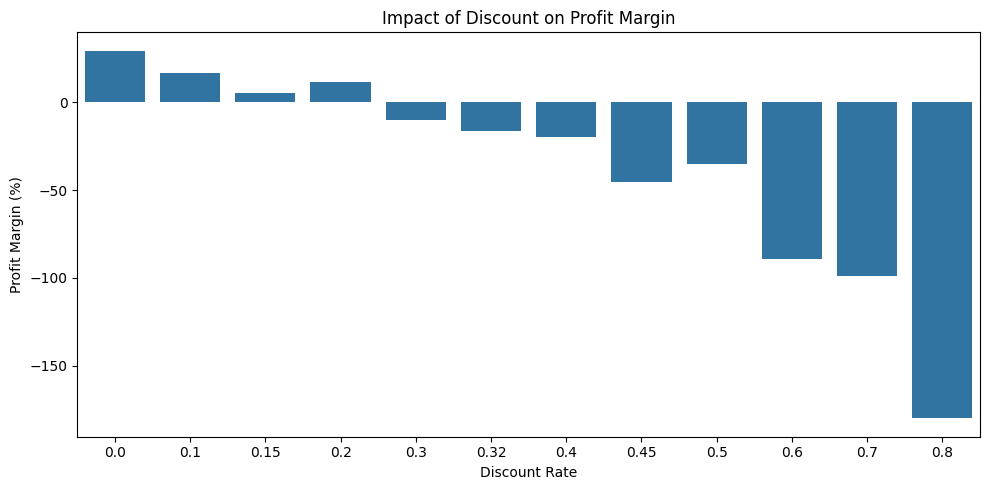

In [21]:

discount_summary = (
    orders.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Transaction_Count=("Row ID", "count")
    )
    .reset_index()
)

discount_summary["Profit_Margin_%"] = (
    discount_summary["Total_Profit"] /
    discount_summary["Total_Sales"]
) * 100

display(discount_summary.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_summary,
    x="Discount",
    y="Profit_Margin_%"
)

plt.title("Impact of Discount on Profit Margin")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()


In [22]:

discount_check = (
    orders.groupby("Discount")
    .agg(
        Transaction_Count=("Row ID", "count"),
        Unique_Orders=("Order ID", "nunique"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

discount_check["Profit_Margin_%"] = (
    discount_check["Profit"] / discount_check["Sales"]
) * 100

display(discount_check.round(2))

print("\nTotal transactions:", discount_check["Transaction_Count"].sum())
print("Total sales:", round(discount_check["Sales"].sum(), 2))
print("Total profit:", round(discount_check["Profit"].sum(), 2))


,Discount,Transaction_Count,Unique_Orders,Sales,Profit,Profit_Margin_%
0,0.00,4798,2644,1087908.47,320987.60,29.51
1,0.10,94,89,54369.35,9029.18,16.61
2,0.15,52,51,27558.52,1418.99,5.15
3,0.20,3657,2407,764594.37,90337.31,11.82
4,0.30,227,211,103226.66,-10369.28,-10.05
5,0.32,27,27,14493.46,-2391.14,-16.50
6,0.40,206,185,116417.78,-23057.05,-19.81
7,0.45,11,10,5484.97,-2493.11,-45.45
8,0.50,66,64,58918.54,-20506.43,-34.80
9,0.60,138,127,6644.70,-5944.66,-89.46



Total transactions: 9994
Total sales: 2297200.86
Total profit: 286397.02


,Category,Discount,Sales,Profit,Transactions,Profit_Margin_%
0,Furniture,0.00,256025.27,58133.08,836,22.71
1,Furniture,0.10,46634.25,7111.01,76,15.25
2,Furniture,0.15,27558.52,1418.99,52,5.15
3,Furniture,0.20,216631.02,6265.95,615,2.89
4,Furniture,0.30,99470.35,-10695.32,222,-10.75
5,Furniture,0.32,14493.46,-2391.14,27,-16.50
6,Furniture,0.40,45614.41,-16187.40,75,-35.49
7,Furniture,0.45,5484.97,-2493.11,11,-45.45
8,Furniture,0.50,20983.47,-12871.20,54,-61.34
9,Furniture,0.60,6644.70,-5944.66,138,-89.46


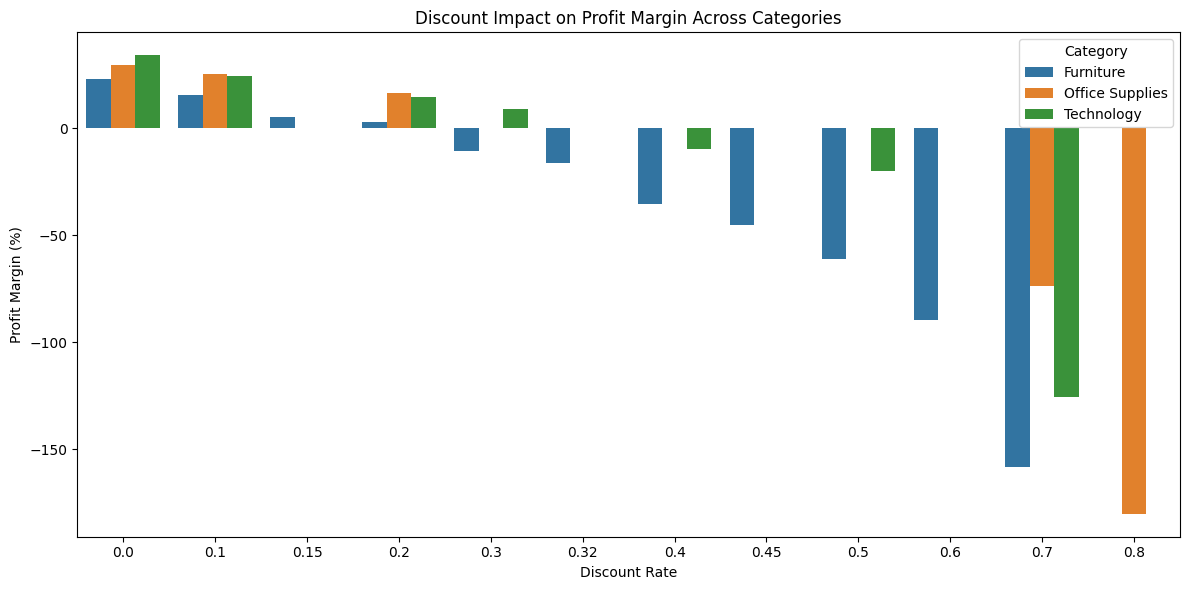

In [23]:

category_discount = (
    orders.groupby(["Category", "Discount"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Transactions=("Row ID", "count")
    )
    .reset_index()
)

category_discount["Profit_Margin_%"] = (
    category_discount["Profit"] /
    category_discount["Sales"]
) * 100

display(category_discount.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_discount,
    x="Discount",
    y="Profit_Margin_%",
    hue="Category"
)

plt.title("Discount Impact on Profit Margin Across Categories")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()


In [24]:

import os

eda_dir = os.path.join(PROJECT_DIR, "reports")

eda_tables = {
    "category_summary": category_summary,
    "monthly_sales": monthly_sales,
    "yearly_summary": yearly_summary,
    "region_summary": region_summary,
    "segment_summary": segment_summary,
    "top_products_by_sales": top_sales,
    "top_products_by_profit": top_profit,
    "discount_summary": discount_check,
    "category_discount_analysis": category_discount
}

for name, df in eda_tables.items():
    df.to_csv(
        os.path.join(eda_dir, f"{name}.csv"),
        index=False
    )

print("EDA analysis tables saved successfully!")
print("Files saved:", len(eda_tables))
print(os.listdir(eda_dir))


EDA analysis tables saved successfully!
Files saved: 9
['top_products_by_profit.csv', 'discount_summary.csv', 'segment_summary.csv', 'category_summary.csv', 'monthly_sales.csv', 'category_discount_analysis.csv', 'top_products_by_sales.csv', 'yearly_summary.csv', 'region_summary.csv', 'figures']


In [25]:

# Reload the final processed dataset
import pandas as pd
import os

processed_dir = os.path.join(PROJECT_DIR, "data/processed")

orders_final = pd.read_csv(
    os.path.join(processed_dir, "orders_clean.csv"),
    parse_dates=["Order Date", "Ship Date"]
)

# Add useful date columns for Power BI
orders_final["Year"] = orders_final["Order Date"].dt.year
orders_final["Month"] = orders_final["Order Date"].dt.month
orders_final["Month Name"] = orders_final["Order Date"].dt.strftime("%B")
orders_final["Quarter"] = (
    "Q" + orders_final["Order Date"].dt.quarter.astype(str)
)
orders_final["YearMonth"] = (
    orders_final["Order Date"].dt.strftime("%Y-%m")
)

# Save the Power BI-ready dataset
powerbi_path = os.path.join(
    processed_dir,
    "superstore_powerbi.csv"
)

orders_final.to_csv(powerbi_path, index=False)

print("Power BI dataset created successfully!")
print("Shape:", orders_final.shape)
print("Missing values:", orders_final.isnull().sum().sum())
print("Unique orders:", orders_final["Order ID"].nunique())
print("Saved at:", powerbi_path)


Power BI dataset created successfully!
Shape: (9994, 27)
Missing values: 0
Unique orders: 5009
Saved at: /content/Sales_Business_Analytics/data/processed/superstore_powerbi.csv


In [26]:
from google.colab import files

files.download(
    "/content/Sales_Business_Analytics/data/processed/superstore_powerbi.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import shutil
import os
from google.colab import files

reports_dir = "/content/Sales_Business_Analytics/reports"
zip_path = "/content/EDA_Analysis_Results.zip"

# Compress the complete reports folder
shutil.make_archive(
    "/content/EDA_Analysis_Results",
    "zip",
    reports_dir
)

print("ZIP file created successfully!")
print("Size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")

# Download
files.download(zip_path)

ZIP file created successfully!
Size: 5.18 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
print(monthly_sales.columns.tolist())
print(monthly_sales.head())

['YearMonth', 'Total_Sales', 'Total_Profit']
  YearMonth  Total_Sales  Total_Profit
0   2014-01    14236.895     2450.1907
1   2014-02     4519.892      862.3084
2   2014-03    55691.009      498.7299
3   2014-04    28295.345     3488.8352
4   2014-05    23648.287     2738.7096


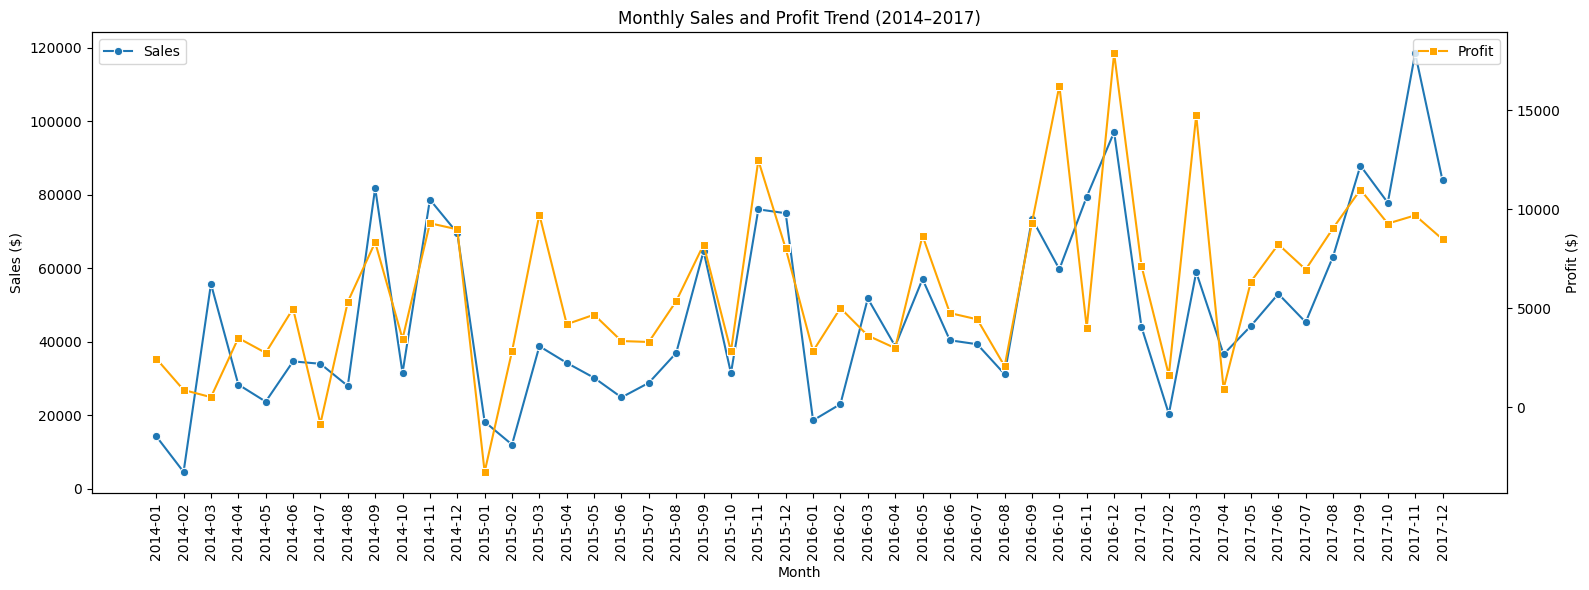

Figure 1 saved successfully!


In [30]:


import matplotlib.pyplot as plt
import seaborn as sns
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")
os.makedirs(figures_dir, exist_ok=True)

monthly_sales = monthly_sales.sort_values("YearMonth")

fig, ax1 = plt.subplots(figsize=(16, 6))

# Monthly sales
sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Sales",
    marker="o",
    ax=ax1,
    label="Sales"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Sales ($)")
ax1.set_title("Monthly Sales and Profit Trend (2014–2017)")
ax1.tick_params(axis="x", rotation=90)

# Monthly profit
ax2 = ax1.twinx()

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="Total_Profit",
    marker="s",
    color="orange",
    ax=ax2,
    label="Profit"
)

ax2.set_ylabel("Profit ($)")

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "monthly_sales_profit_trend.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 saved successfully!")


In [32]:
print(yearly_summary.columns.tolist())
print(yearly_summary.head())

['Year', 'Total_Sales', 'Total_Profit', 'Total_Orders', 'Sales_Growth_%', 'Profit_Growth_%']
   Year  Total_Sales  Total_Profit  Total_Orders  Sales_Growth_%  \
0  2014  484247.4981    49543.9741           969             NaN   
1  2015  470532.5090    61618.6037          1038       -2.832227   
2  2016  609205.5980    81795.1743          1315       29.471521   
3  2017  733215.2552    93439.2696          1687       20.355962   

   Profit_Growth_%  
0              NaN  
1        24.371540  
2        32.744284  
3        14.235675  


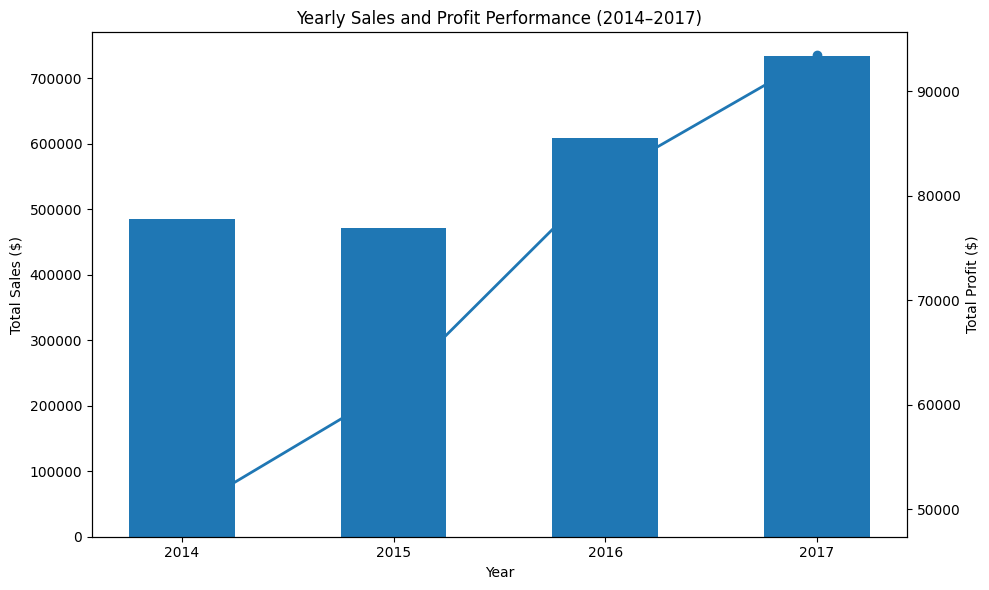

Figure 2 corrected and saved successfully!


In [34]:

import matplotlib.pyplot as plt
import numpy as np
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

# Treat years as categories
years = yearly_summary["Year"].astype(str)
x = np.arange(len(years))

fig, ax1 = plt.subplots(figsize=(10, 6))

# Sales bars
ax1.bar(
    x,
    yearly_summary["Total_Sales"],
    width=0.5,
    label="Sales"
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Total Sales ($)")
ax1.set_xticks(x)
ax1.set_xticklabels(years)
ax1.set_title("Yearly Sales and Profit Performance (2014–2017)")

# Profit line on secondary axis
ax2 = ax1.twinx()

ax2.plot(
    x,
    yearly_summary["Total_Profit"],
    marker="o",
    linewidth=2,
    label="Profit"
)

ax2.set_ylabel("Total Profit ($)")

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "yearly_sales_profit_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 corrected and saved successfully!")


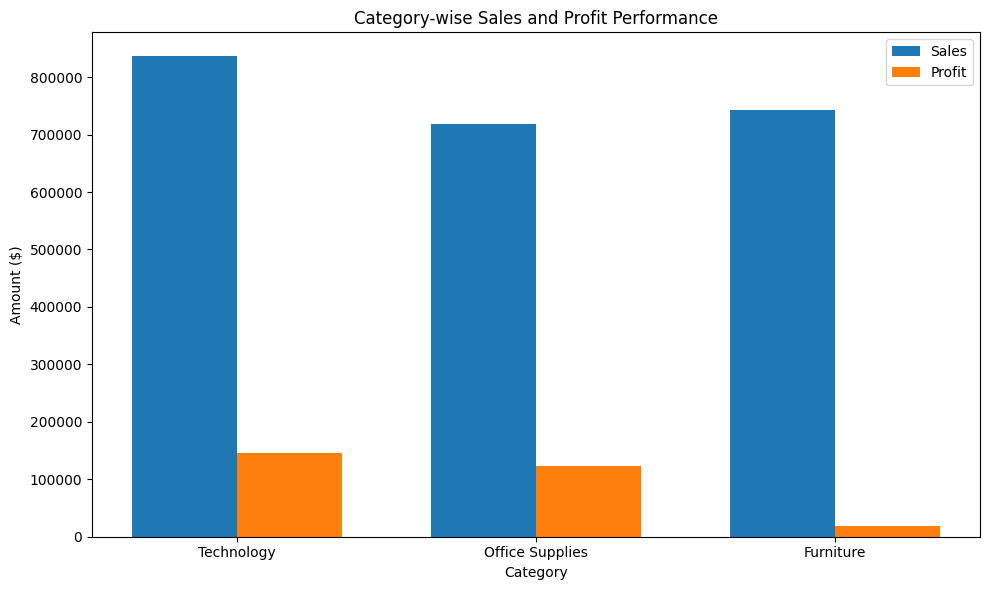

Figure 3 saved successfully!


In [35]:

import matplotlib.pyplot as plt
import numpy as np
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

categories = category_summary["Category"]
x = np.arange(len(categories))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Sales bars
ax1.bar(
    x - width/2,
    category_summary["Total_Sales"],
    width,
    label="Sales"
)

# Profit bars
ax1.bar(
    x + width/2,
    category_summary["Total_Profit"],
    width,
    label="Profit"
)

ax1.set_xlabel("Category")
ax1.set_ylabel("Amount ($)")
ax1.set_title("Category-wise Sales and Profit Performance")
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "category_sales_profit_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully!")


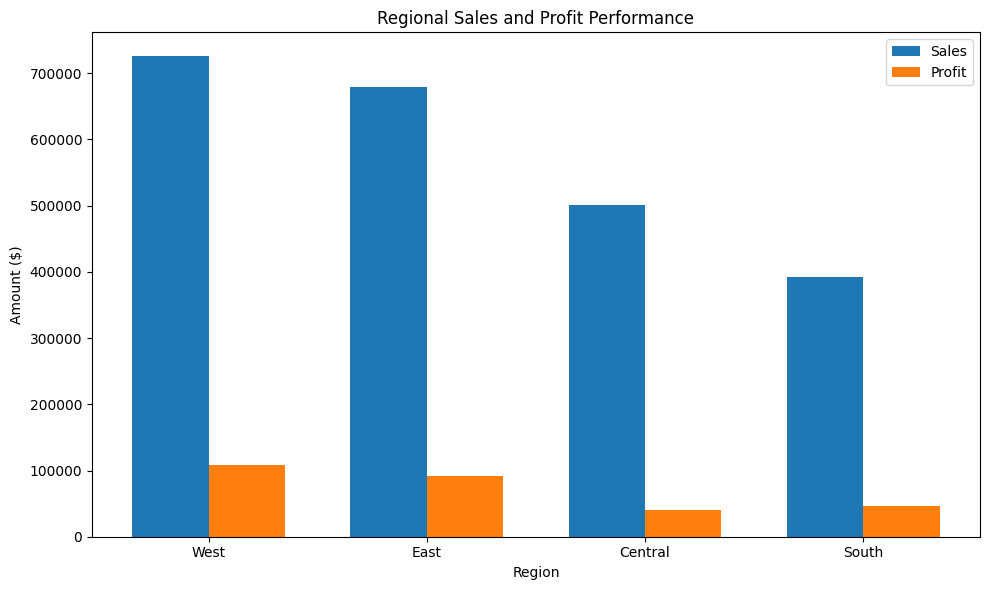

Figure 4 saved successfully!


In [36]:

import matplotlib.pyplot as plt
import numpy as np
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

regions = region_summary["Region"]
x = np.arange(len(regions))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    region_summary["Total_Sales"],
    width,
    label="Sales"
)

ax.bar(
    x + width/2,
    region_summary["Total_Profit"],
    width,
    label="Profit"
)

ax.set_xlabel("Region")
ax.set_ylabel("Amount ($)")
ax.set_title("Regional Sales and Profit Performance")
ax.set_xticks(x)
ax.set_xticklabels(regions)
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "regional_sales_profit_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 4 saved successfully!")


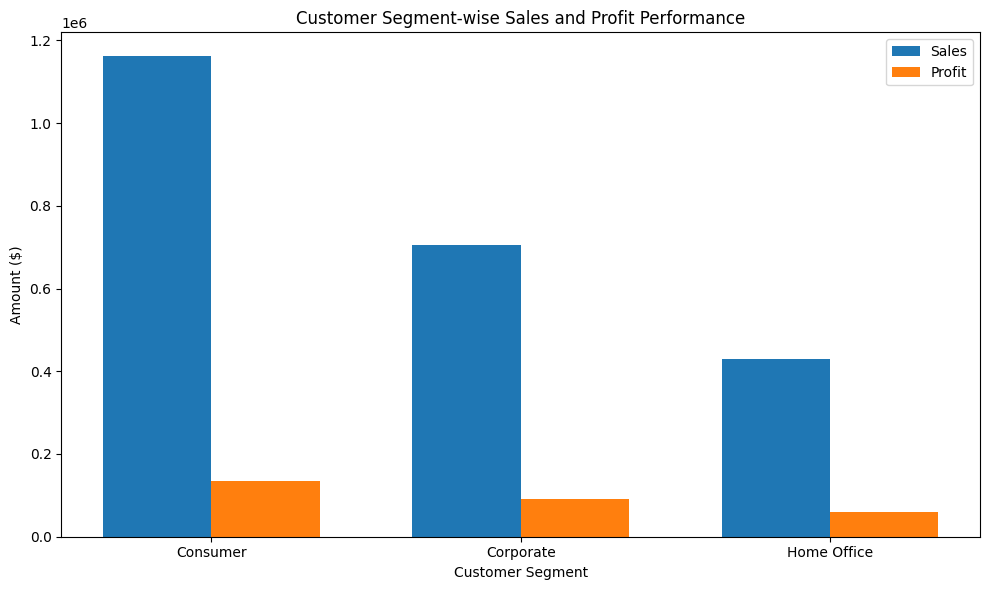

Figure 5 saved successfully!


In [37]:

import matplotlib.pyplot as plt
import numpy as np
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

segments = segment_summary["Segment"]
x = np.arange(len(segments))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    segment_summary["Total_Sales"],
    width,
    label="Sales"
)

ax.bar(
    x + width/2,
    segment_summary["Total_Profit"],
    width,
    label="Profit"
)

ax.set_xlabel("Customer Segment")
ax.set_ylabel("Amount ($)")
ax.set_title("Customer Segment-wise Sales and Profit Performance")
ax.set_xticks(x)
ax.set_xticklabels(segments)
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "customer_segment_performance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 5 saved successfully!")


In [39]:
print(top_sales.columns.tolist())
print(top_sales.head(3))

['Product ID', 'Product Name', 'Category', 'Total_Sales', 'Total_Profit', 'Total_Quantity']
           Product ID                                       Product Name  \
1640  TEC-CO-10004722              Canon imageCLASS 2200 Advanced Copier   
787   OFF-BI-10003527  Fellowes PB500 Electric Punch Plastic Comb Bin...   
1669  TEC-MA-10002412  Cisco TelePresence System EX90 Videoconferenci...   

             Category  Total_Sales  Total_Profit  Total_Quantity  
1640       Technology    61599.824    25199.9280              20  
787   Office Supplies    27453.384     7753.0390              31  
1669       Technology    22638.480    -1811.0784               6  


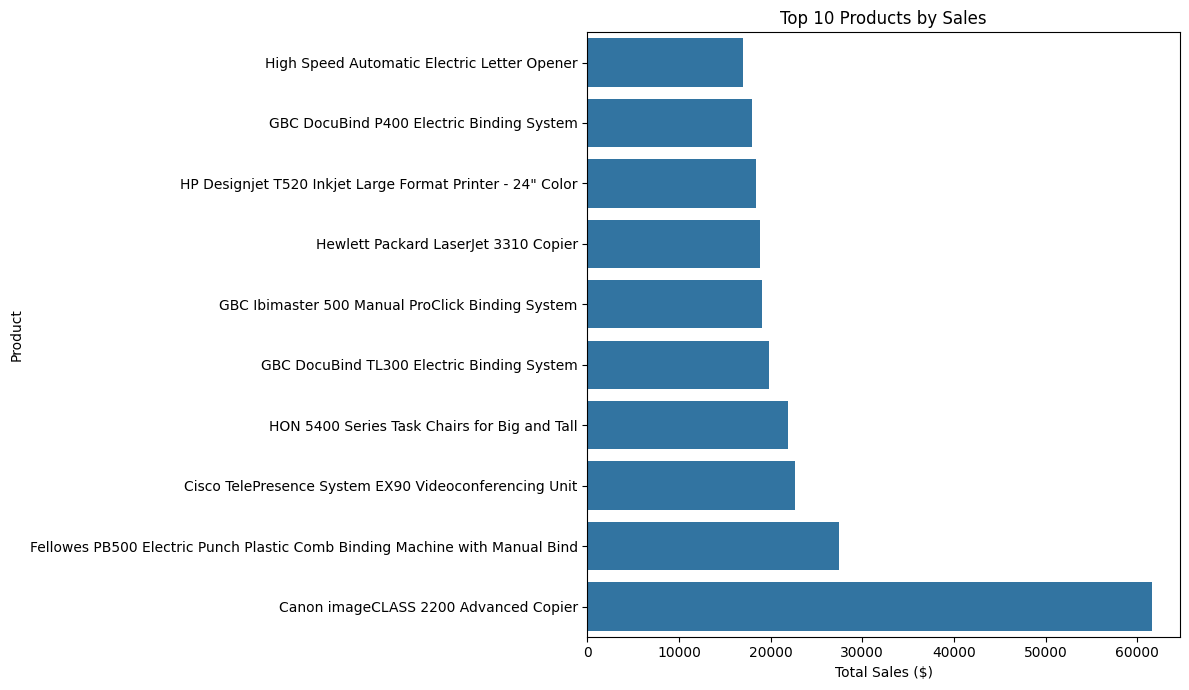

Figure 6 saved successfully!


In [40]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

top10_sales = (
    top_sales.nlargest(10, "Total_Sales")
    .sort_values("Total_Sales")
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10_sales,
    x="Total_Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "top_10_products_by_sales.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 6 saved successfully!")


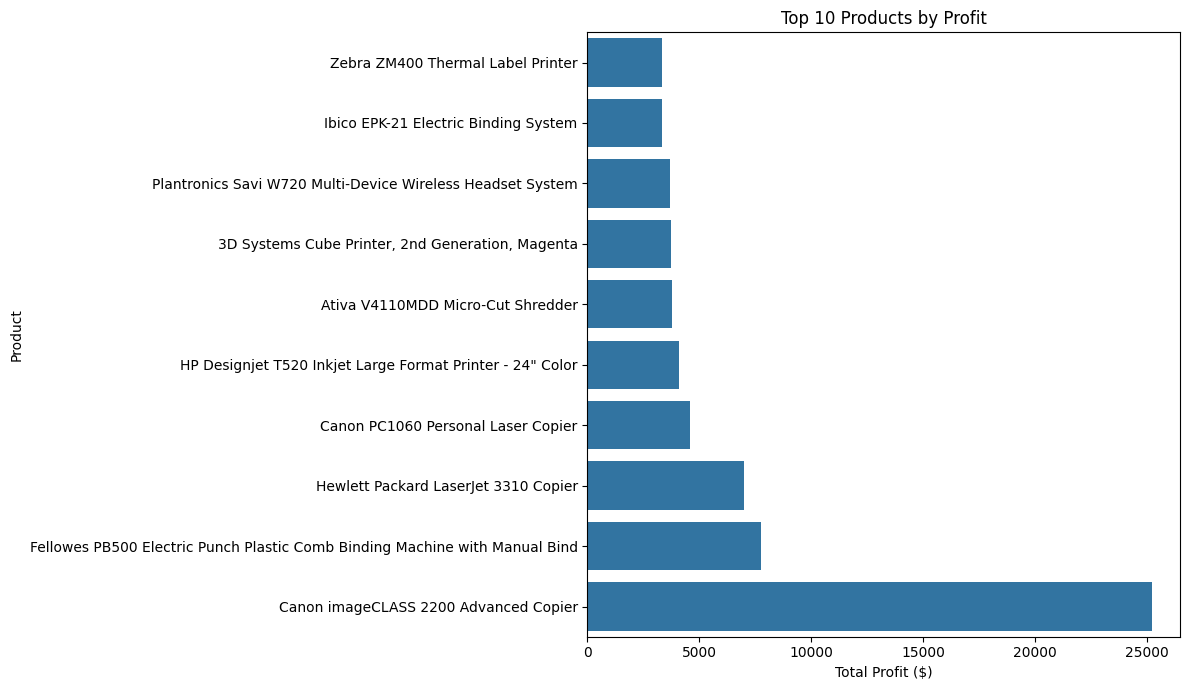

Figure 7 saved successfully!


In [41]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

top10_profit = (
    top_profit.nlargest(10, "Total_Profit")
    .sort_values("Total_Profit")
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10_profit,
    x="Total_Profit",
    y="Product Name"
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product")

plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "top_10_products_by_profit.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 7 saved successfully!")


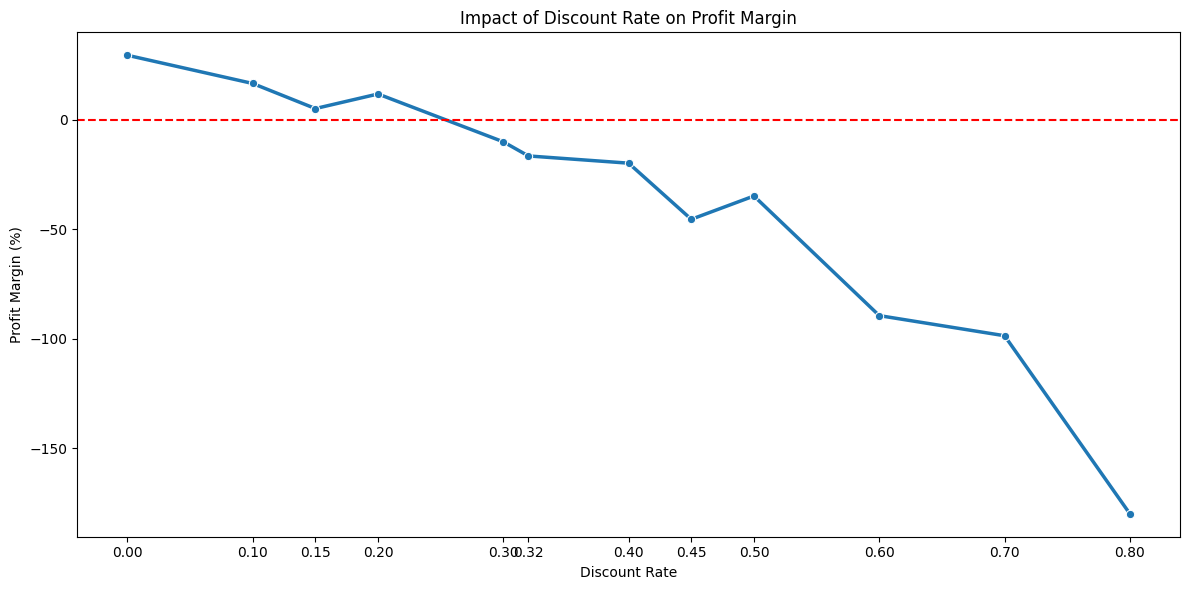

Figure 8 saved successfully!


In [42]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=discount_check,
    x="Discount",
    y="Profit_Margin_%",
    marker="o",
    linewidth=2.5
)

plt.axhline(y=0, linestyle="--", color="red")

plt.title("Impact of Discount Rate on Profit Margin")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")
plt.xticks(discount_check["Discount"])
plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "discount_impact_on_profit_margin.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 8 saved successfully!")


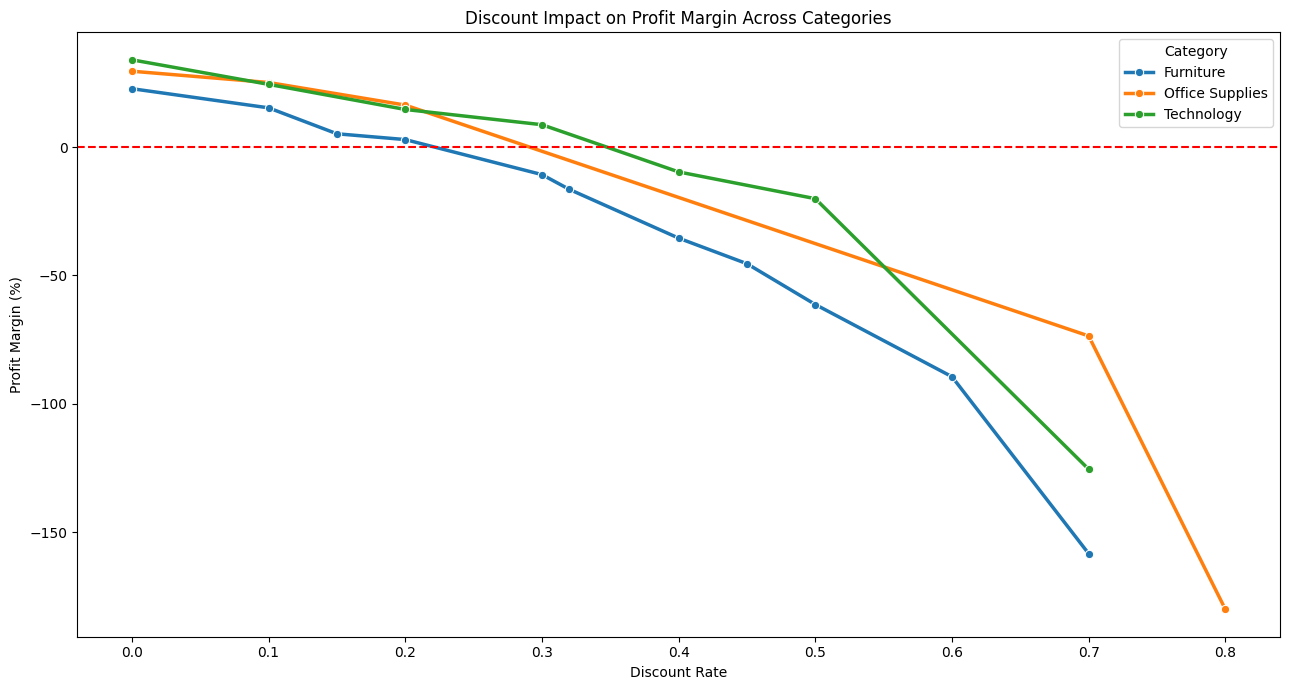

Figure 9 saved successfully!


In [43]:

import matplotlib.pyplot as plt
import seaborn as sns
import os

figures_dir = os.path.join(PROJECT_DIR, "reports/figures")

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=category_discount,
    x="Discount",
    y="Profit_Margin_%",
    hue="Category",
    marker="o",
    linewidth=2.5
)

plt.axhline(y=0, linestyle="--", color="red")

plt.title("Discount Impact on Profit Margin Across Categories")
plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")
plt.legend(title="Category")
plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "category_discount_impact.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 9 saved successfully!")


In [44]:

import os

reports_dir = os.path.join(PROJECT_DIR, "reports")
figures_dir = os.path.join(reports_dir, "figures")

print("EDA CSV files:")
csv_files = [f for f in os.listdir(reports_dir) if f.endswith(".csv")]

for f in sorted(csv_files):
    print("✓", f)

print("\nEDA Figures:")
figure_files = [f for f in os.listdir(figures_dir) if f.endswith(".png")]

for f in sorted(figure_files):
    print("✓", f)

print("\nTotal CSV files:", len(csv_files))
print("Total figures:", len(figure_files))


EDA CSV files:
✓ category_discount_analysis.csv
✓ category_summary.csv
✓ discount_summary.csv
✓ monthly_sales.csv
✓ region_summary.csv
✓ segment_summary.csv
✓ top_products_by_profit.csv
✓ top_products_by_sales.csv
✓ yearly_summary.csv

EDA Figures:
✓ category_discount_impact.png
✓ category_sales_profit_performance.png
✓ customer_segment_performance.png
✓ discount_impact_on_profit_margin.png
✓ monthly_sales_profit_trend.png
✓ regional_sales_profit_performance.png
✓ top_10_products_by_profit.png
✓ top_10_products_by_sales.png
✓ yearly_sales_profit_performance.png

Total CSV files: 9
Total figures: 9


In [45]:

import shutil
import os
from google.colab import files

reports_dir = os.path.join(PROJECT_DIR, "reports")
zip_path = "/content/EDA_Complete_Results.zip"

# Include all 9 CSVs and 9 PNG figures
shutil.make_archive(
    "/content/EDA_Complete_Results",
    "zip",
    root_dir=reports_dir
)

print("ZIP created successfully!")
print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

files.download(zip_path)


ZIP created successfully!
File size: 1.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>